# Vision Generative AI Comparison: Stable Diffusion in Jupyter Notebook

This notebook demonstrates text-to-image generation and image-to-image editing with Stable Diffusion. The same three prompts should also be entered into a second Vision GAI interface (for example, ChatGPT image generation or another approved interface) so the outputs can be compared fairly.

## Import libraries and select the device

The code imports the image-generation tools, tells Hugging Face to use its standard download method, then selects a compute device: CUDA or Apple MPS with float16, otherwise CPU with float32. It prints the selected device

In [ ]:
import os

os.environ["HF_HUB_DISABLE_XET"] = "1"

import torch
from diffusers import AutoPipelineForText2Image, AutoPipelineForImage2Image
from PIL import Image
from IPython.display import display

if torch.cuda.is_available():
    device = 'cuda'
    dtype = torch.float16
elif torch.backends.mps.is_available():
    device = 'mps'
    dtype = torch.float16
else:
    device = 'cpu'
    dtype = torch.float32

print('Device:', device)


Device: mps


## Define the prompt

In [7]:
prompt = 'Create an image of a photorealistic luxury modern living room with floor-to-ceiling windows overlooking a beautiful city skyline, elegant cream-colored sectional sofa, large textured area rug, natural wood coffee table, marble accent wall, contemporary designer furniture, warm indirect lighting, large indoor plants, sophisticated neutral color palette, expensive high-end interior design, realistic materials and shadows, cinematic interior photography, highly detailed, wide-angle composition, 8K photography, no people, no text'


## Load Stable Diffusion

Stable Diffusion is an AI model that creates images from text prompts. It starts with random noise and gradually refines it into an image guided by the prompt. It can also edit existing images based on instructions.

This cell loads the SDXL text-to-image model using settings for the selected device, then moves it onto that device. If loading fails, it shows guidance about checking connectivity, disk space.

In [ ]:
MODEL_ID = 'stabilityai/stable-diffusion-xl-base-1.0'
model_load_options = {
    'dtype': dtype,
    'use_safetensors': True,
    'low_cpu_mem_usage': True,
    'token': os.getenv('HF_TOKEN') or None,
}
if dtype == torch.float16:
    model_load_options['variant'] = 'fp16'

print(f'Loading {MODEL_ID} on {device}. The initial download can take several minutes.')
try:
    pipe = AutoPipelineForText2Image.from_pretrained(MODEL_ID, **model_load_options)
    pipe = pipe.to(device)
except Exception as exc:
    raise RuntimeError(
        'Stable Diffusion could not be loaded. Check your internet connection and free disk space. '
    ) from exc

print('Stable Diffusion pipeline loaded.')


Loading stabilityai/stable-diffusion-xl-base-1.0 on mps. The initial download can take several minutes.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Stable Diffusion pipeline loaded.


## Generate the Stable Diffusion images

This code generates an image from the prompt using Stable Diffusion, saves it as stable_diffusion_outputs/living_room.png, stores it in generated, and displays it. The seed makes the generation reproducible.

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (95 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['interior photography , highly detailed , wide - angle composition , 8 k photography , no people , no text']
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (95 > 77). Running this sequence through the model will result in indexing errors
The following part of your input was truncated because CLIP can only handle sequences up to 77 tokens: ['interior photography , highly detailed , wide - angle composition , 8 k photography , no people , no text']


  0%|          | 0/30 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


stable_diffusion_outputs/living_room.png


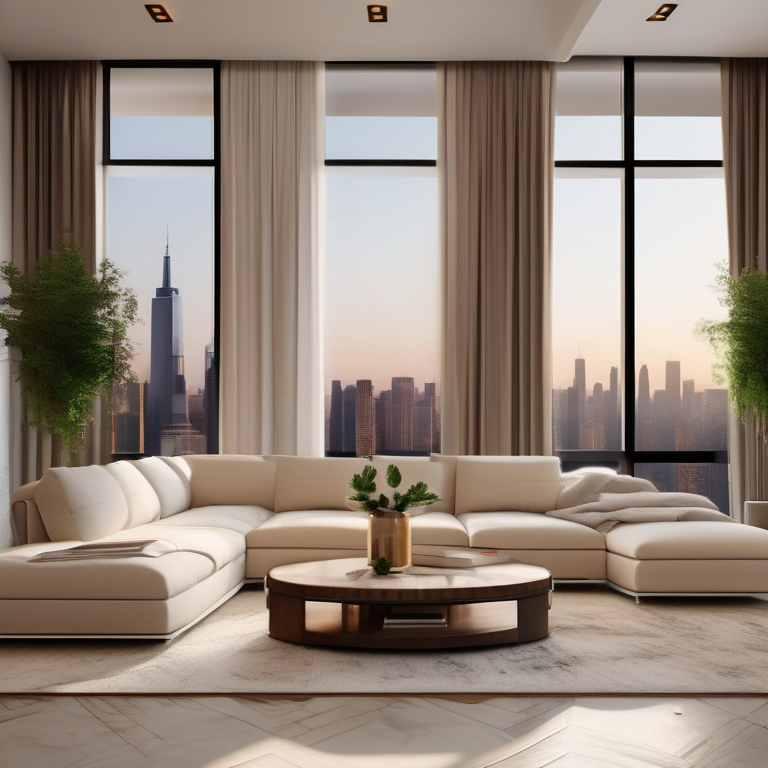

In [9]:
os.makedirs('stable_diffusion_outputs', exist_ok=True)

seed = 12345
generator = torch.Generator(device=device).manual_seed(seed)

generated = {}

result = pipe(
    prompt=prompt,
    num_inference_steps=30,
    guidance_scale=7.0,
    height=768,
    width=768,
    generator=generator
).images[0]
path = f'stable_diffusion_outputs/living_room.png'
result.save(path)
generated['living_room'] = result
print(path)
display(result)


## Edit one generated image with image-to-image diffusion

This code loads the image-editing pipeline, changes the generated living room image using the prompt, then saves and displays the edited result. The seed makes the edit reproducible.

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  0%|          | 0/13 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


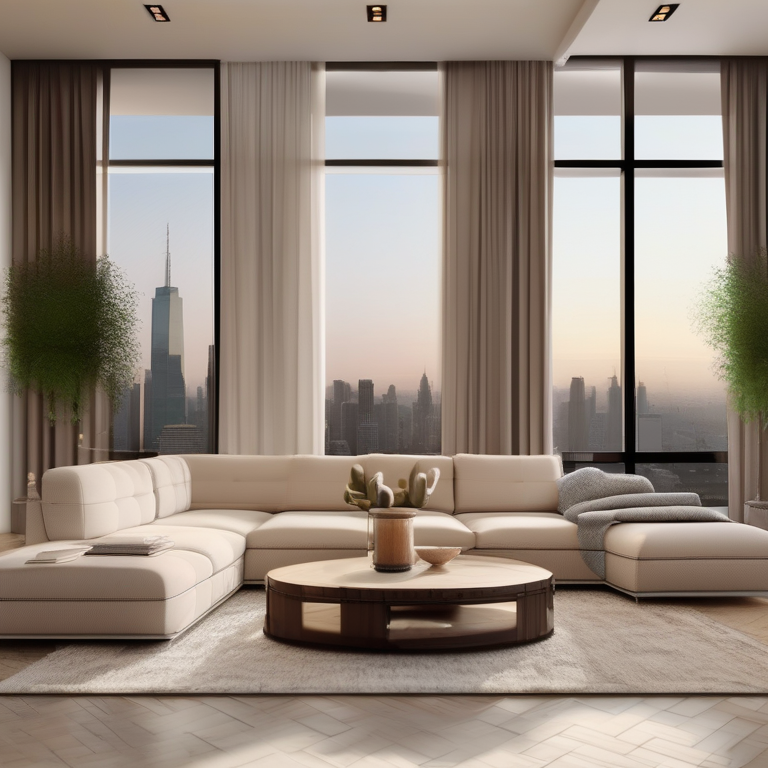

stable_diffusion_outputs/living_room_edited.png


In [11]:
img2img = AutoPipelineForImage2Image.from_pretrained(
    MODEL_ID,
    torch_dtype=dtype,
    use_safetensors=True
)
img2img = img2img.to(device)

source_image = generated['living_room'].resize((768, 768))
edit_prompt = 'Change the color of sofa to black and put a modern abstract painting on the wall above the sofa, while keeping the rest of the living room intact.'

edited = img2img(
    prompt=edit_prompt,
    image=source_image,
    strength=0.45,
    guidance_scale=7.0,
    num_inference_steps=30,
    generator=torch.Generator(device=device).manual_seed(54321)
).images[0]

edited_path = 'stable_diffusion_outputs/living_room_edited.png'
edited.save(edited_path)
display(edited)
print(edited_path)
